# Class 5a - Geospatial Data (`netCDF` & `xarray`)

Recommended documentation: [Geospatial course from UGhent](https://github.com/plovercode/DS-python-geospatial/tree/main/notebooks)


Today we move from time-series tabular data (`pandas`, Class 4) to multi-dimensional gridded data.

Goals:
- understand what a `netCDF` file is and how to read it with  xarray,
- select, slice, reduce, filter, and resample gridded temperature data

## 1. From pandas to xarray

In Class 4, each row was one time step and each column was one variable (temperature, humidity, …). That works well for a point station.

Gridded climate data has more axes, generally they have coordinates with different possible resolutions:

- time (e.g. hourly, weekly, monthly...),
- latitude and longitude (e.g. 1km x 1km),

and one or more data variables (e.g. temperature, precipitation...).

`Pandas` is only useful for two-dimensional datasets. In this course, we will learn how to use another library specifically designed to handle multidimensional datasets: `xarray`.

`xarray` use `Dataset` and `DataArray` variables types:

![xarray Dataset: data variables, coordinates, and attributes](img/xarray-dataset.png)

*Figure: an `xarray.Dataset` can hold several data variables that share coordinates (e.g. lon, lat, time), plus metadata in attributes. (Source: [xarray documentation](https://docs.xarray.dev/).)*

In [ ]:
import matplotlib.pyplot as plt # for plotting
import xarray as xr

## 2. Opening a netCDF with xarray

We use Future Forests predicted 2 m air temperature (`pred_temperature_C`) for January 2024 on a ~100 m grid at an hourly resolution provided by Christopher Jung.

The raw file is stored in projected coordinates (EPSG:25832, ETRS89 / UTM zone 32N). For class, we use a pre-processed lon/lat (WGS84) version:

In [ ]:
ls ../processed_data/pred_temperature_C_2024_01_wgs84.nc

`xr.open_dataset` reads the file and returns a Dataset: a dictionary-like container of labelled arrays (DataArrays) that share dimensions.

In [ ]:
DataPath = '../processed_data/pred_temperature_C_2024_01_wgs84.nc'
TempDs = xr.open_dataset(filename_or_obj=DataPath, chunks='auto') # chunks='auto' is to optimize how to better manage memory
print(type(TempDs))
print(TempDs)

On the output above we can observe:
1. There are 3 dimensions which are the 3 coordinates; `time` of size 744 (why?), `lat` of size 2132 and `lon` of size 1701.
2. There are two data variables, but only one is usable (`crs` is for metadata): `pred_temperature_C` of shape `(time, lat, lon)`

Let's select the variable that interests us (there is only one variable in this file but there could be multiple):

In [ ]:
Temp = TempDs['pred_temperature_C']
print(type(Temp))
print(Temp.dims)

`Temp` is a `DataArray`, an array of one variable (unlike the `Dataset`, which can hold several variables at once) with its own dimension names (`time`, `lat`, `lon`), coordinate arrays (`Temp.time`, `Temp.lat`, `Temp.lon`) and many other "methods" like `.dims`.

## 3. Selecting data

Similarly to `pandas`, there are two ways to select and slice data with `xarray`:

1. `.isel(...)` select by integer position (like NumPy indexing)

In [ ]:
FirstMap = Temp.isel(time=0)
print(FirstMap.dims)

Quick map of the first time step with matplotlib. For a 2D grid (lon × lat), use `plt.pcolormesh` to colour each cell

In [ ]:
# plt.pcolormesh(lon, lat, value)
plt.pcolormesh(FirstMap.lon, FirstMap.lat, FirstMap, cmap='coolwarm')

plt.colorbar(label='Temperature (°C)')
plt.title('Predicted 2 m temperature at t=0')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

plt.show()

2. `.sel(...)` select by coordinate label (like pandas `.loc`)

`.sel` works on any coordinate, including `time`. Pass a calendar string:

In [ ]:
NoonMap = Temp.sel(time='2024-01-15T12:00')
print(NoonMap.dims)

In [ ]:
plt.pcolormesh(NoonMap.lon, NoonMap.lat, NoonMap, cmap='coolwarm')

plt.colorbar(label='Temperature (°C)')
plt.title('Predicted 2 m temperature at noon')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

plt.show()


We can also use `.sel` on the (`lon`, `lat`) coordinates.

In Class 4 you worked with hourly data from the Hartheim climate station. We can extract the same location from the gridded map (~7.60°E, 47.93°N). The model grid will not contain that exact lon/lat pair, so we use `method="nearest"` to snap to the closest grid cell:

In [ ]:
HartheimSeries = Temp.sel(lon=7.6, lat=47.93, method='nearest')
print(HartheimSeries.dims)

Now we can make a figure of `HartheimSeries`. Which kind of figure should we make?

In [ ]:
plt.plot(HartheimSeries.time, HartheimSeries) # the x variable can be retrieved with .time

plt.ylabel('Temperature (°C)')
plt.title('Hartheim, hourly predicted temperature, January 2024')
plt.xticks(rotation=45)

plt.show()

Try to select the predicted temperature at Hartheim on 18 January 2024 at 9pm

In [71]:
# Solution
HartheimNoon = Temp.sel(lon=7.6, lat=47.93, time='2024-01-18T21:00', method='nearest')
print(HartheimNoon.values)

0.49194357


## 4. Slicing data

So far we selected a single time step (`.isel` by position, or `.sel` by calendar label) or a single grid point (`.sel` with `method="nearest"`). Often you want a sub-region: a box in lon/lat, or a time window.

Inside `.sel(...)`, pass Python's built-in `slice(start, stop)` for ranges, the same idea as `df.loc['2024-01-01':'2024-01-07']` in pandas:

- `slice(7.5, 8.1)` on `lon` keeps all cells between 7.5°E and 8.1°E and `slice(48.15, 47.75)` on `lat` keeps all cells between 48.15°N and 47.75°N:

In [ ]:
print("before:", Temp.sizes)
FreiburgBox = Temp.sel(lon=slice(7.5, 8.1), lat=slice(48.15, 47.75))
print("after:", FreiburgBox.sizes)

In [ ]:
BoxMap = FreiburgBox.isel(time=0)

plt.pcolormesh(BoxMap.lon, BoxMap.lat, BoxMap, cmap='coolwarm')
plt.colorbar(label='Temperature (°C)')
plt.title('Freiburg–Hartheim box, one timestep')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

plt.show()

- `slice('2024-01-01', '2024-01-07')` on `time` keeps that calendar window:

In [ ]:
print("before:", Temp.sizes)
FirstWeek = Temp.sel(time=slice('2024-01-01', '2024-01-07'))
print("after:", FirstWeek.sizes)

> Note: for latitude, values decrease north to south, this is not always the case.


Try to select temperatures around Karlsruhe (`lon` 8.2–8.6, `lat` 49.15–48.85) for the second week of January (8–14 January 2024)

In [ ]:
# Solution
KarlsruheBox = Temp.sel(
    lon=slice(8.2, 8.6),
    lat=slice(49.15, 48.85),
    time=slice('2024-01-08', '2024-01-14'),
)
print(KarlsruheBox.sizes)

## 5. Reduction

Let's say you want a map of the January temperature average. You have hourly values at every grid cell, so you need to collapse the time dimension and keep the spatial ones.

Reductions such as `.mean()`, `.min()`, `.max()` can run along one dimension:

In [ ]:
JanMeanMap = Temp.mean('time')
print(JanMeanMap.dims)

In [ ]:
plt.pcolormesh(JanMeanMap.lon, JanMeanMap.lat, JanMeanMap, cmap='coolwarm')
plt.colorbar(label='Temperature (°C)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

Now ask how the region as a whole evolved during January. This time you collapse lat and lon and keep time, which leaves you with a single time series instead of a map:

In [72]:
BoxSpatialMean = FreiburgBox.mean(('lat', 'lon'))
print(BoxSpatialMean.dims)

('time',)


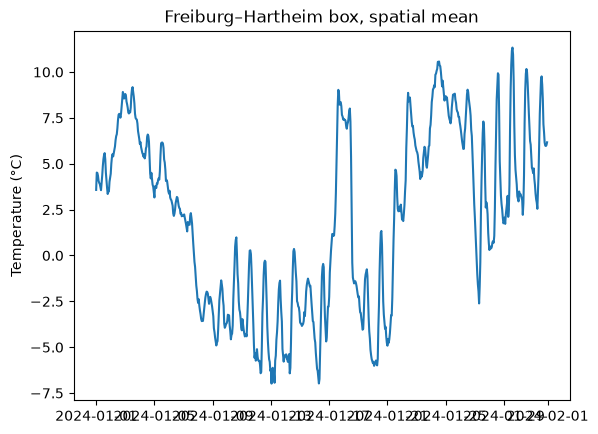

In [73]:
plt.plot(BoxSpatialMean.time, BoxSpatialMean)
plt.ylabel('Temperature (°C)')
plt.title('Freiburg–Hartheim box, spatial mean')
plt.show()

## Exercise A

Similarly to what we have done above, try to reduce the right dimension to make a zonal mean (or latitudinal) plot with `FreiburgBox`. If you don't know what it is, use Google image!

('lat',)


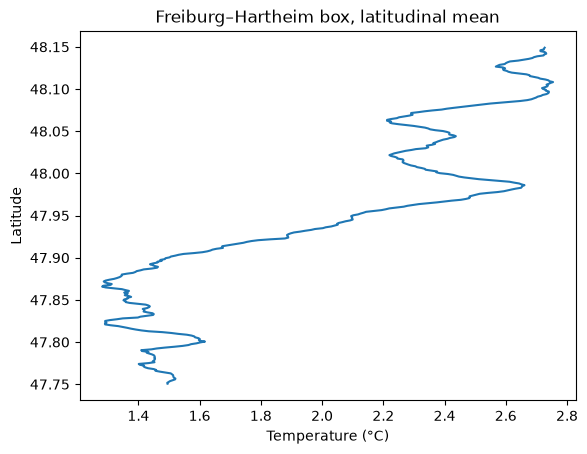

In [66]:
# Solution
BoxLatitudinalMean = FreiburgBox.mean(('lon', 'time'))
print(BoxLatitudinalMean.dims)

plt.plot(BoxLatitudinalMean, BoxLatitudinalMean.lat)
plt.ylabel('Latitude')
plt.xlabel('Temperature (°C)')
plt.title('Freiburg–Hartheim box, latitudinal mean')
plt.show()

## 6. Changing time resolution (`resample`)

In Class 4, you used `.resample('D').mean()` on the Hartheim station table to go from hourly to daily values. `xarray` does the same on gridded data: group timestamps into coarser bins, then aggregate, e.g. `resample(time="1D")` resample to day bins (then `.mean()`, `.sum()`, …)

The frequency strings differ slightly from pandas (`"1D"` vs `"D"`), but the idea is unchanged: change the time resolution, then reduce.


In [ ]:
BoxSeries = FreiburgBox.mean(('lat', 'lon'))

Daily = BoxSeries.resample(time='1D').mean()

plt.plot(Daily.time, Daily, marker='o')
plt.ylabel('Temperature (°C)')
plt.title('Freiburg–Hartheim box, daily mean temperature, January 2024')
plt.xticks(rotation=45)
plt.show()

## 7. Filtering / masking with `.where`

In Class 3b, you filtered NumPy arrays with a Boolean mask with `np.where(condition, value_if_true, np.nan)`.

xarray's `.where(condition)` does the same thing on a `DataArray`: it keeps values where the condition is `True` and sets the rest to `NaN` (grid shape unchanged, useful for maps).


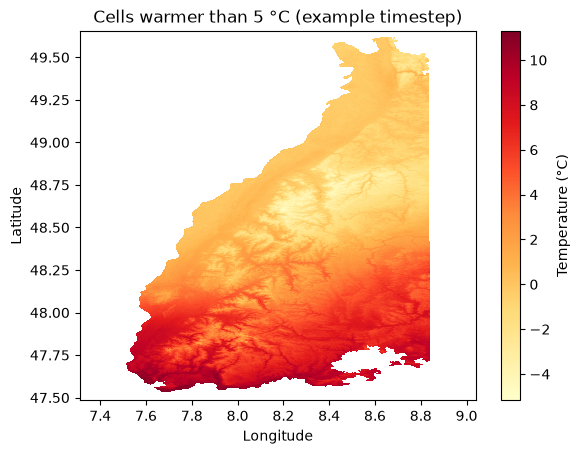

In [ ]:
# I only want temperature above 5 °C
WarmCells = Temp.where(Temp > 5)

WarmMap = WarmCells.sel(time='2024-01-18T12:00') # example timestep
plt.pcolormesh(WarmMap.lon, WarmMap.lat, WarmMap, cmap='YlOrRd')
plt.colorbar(label='Temperature (°C)')
plt.title('Cells warmer than 5 °C (example timestep)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

## Exercise B

Foresters are going to cut trees on a specific region (`lon=7.5→8.1`, `lat=48.15→47.75`), on a specific date (`2024-01-20T14:00`). They ask you to make a map of the area that are frozen (where they cannot use their tools).

In [ ]:
# Solution
CollectWoodDate = Temp.sel(lon=slice(7.5, 8.1), lat=slice(48.15, 47.75)).sel(time='2024-01-20T14:00', method='nearest')
BelowZero = CollectWoodDate.where(CollectWoodDate < 0)

plt.pcolormesh(BelowZero.lon, BelowZero.lat, BelowZero, cmap='Blues_r')
plt.colorbar(label='Temperature (°C)')
plt.title('20 Jan 14:00, cells below 0 °C')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

### Geographic masks

The example above used a value mask (`Temp > 5`): a field of `True`/`False` values, like the Boolean masks in Class 4.You can also mask by location (e.g. you have data over Germany and only want to focus to the BW region). 

For Freiburg city, we prepared a Boolean mask on the same lon/lat grid (`freiburg_city_mask.nc` in `processed_data/`, built from the OpenStreetMap city boundary). Load it with `xr.open_dataarray` like this:

In [ ]:
InFreiburg = xr.open_dataarray('../processed_data/freiburg_city_mask.nc')

Then pass it to `.where(...)`, same pattern as before, but the condition comes from a file instead of `Temp > 5`:

In [ ]:
TempMasked = Temp.where(InFreiburg)

# Select one time-step and zoom
CityMap = TempMasked.sel(time='2024-01-18T12:00', lon=slice(7.65, 7.95), lat=slice(48.1, 47.85))

# Plot
plt.pcolormesh(CityMap.lon, CityMap.lat, CityMap, cmap='coolwarm')
plt.colorbar(label='Temperature (°C)')
plt.title('Predicted temperature inside Freiburg city at noon')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

## Exercise C

City trees are known to leaf out earlier and to suffer more summer drought stress than the same species a few kilometres outside, and one suspected reason is that cities are warmer than their surroundings. Warmer winters also matter for forest health: they let insect pests overwinter more successfully.

You have a Boolean mask of Freiburg city (`InFreiburg`) on the same grid, so you can compare the city with the countryside around it. 

Tasks:

1. Build two hourly time series: the spatial mean inside the city, and the spatial mean outside the city (tip: instead of `.where(InFreiburg)`, use `.where(InFreiburg == False)`). Plot the two series as daily means on the same figure, with a legend.

In [ ]:
# Solution
InFreiburg = xr.open_dataarray('../processed_data/freiburg_city_mask.nc')

# Mask city
CityOnly = Temp.where(InFreiburg)
CitySeries = CityOnly.mean(('lat', 'lon'))

# Mask rural
RuralOnly = Temp.where(InFreiburg == False)
RuralSeries = RuralOnly.mean(('lat', 'lon'))

# Resample to daily values
CityDaily = CitySeries.resample(time='1D').mean()
RuralDaily = RuralSeries.resample(time='1D').mean()

# Plot
plt.plot(CityDaily.time, CityDaily, label='Inside Freiburg')
plt.plot(RuralDaily.time, RuralDaily, label='Outside Freiburg')
plt.ylabel('Temperature (°C)')
plt.title('Daily mean temperature, January 2024')
plt.xticks(rotation=45)
plt.legend()
plt.show()

2. Compute the hourly difference (city minus countryside), plot it, and add a horizontal line at 0 °C (`plt.axhline`)

In [ ]:
# Solution
# Difference
DiffSeries = CitySeries - RuralSeries

# Plot
plt.plot(DiffSeries.time, DiffSeries)
plt.axhline(y=0, color='grey', linestyle='--')
plt.ylabel('City − countryside (°C)')
plt.title('Urban heat island intensity, hourly')
plt.xticks(rotation=45)
plt.show()

## Exercise D

On clear winter nights, cold air sinks and pools in valleys. The air layer near the ground can become colder than the air higher up, i.e. a temperature inversion. Fog often fills the Rhine valley while the Black Forest ridges (e.g. Schauinsland, ~1 280 m) stay clear and can feel warmer.

We prepared a DEM on the same lon/lat grid: `elevation_m_wgs84.nc` in `processed_data/`. Work in the Freiburg box (`lon=7.6, 8.1`, `lat=48.15, 47.75`).

1. Load the DEM and make a map of elevation (`cmap="Greys_r"` is a good choice)

In [ ]:
# Solution
# Open data
Elev = xr.open_dataarray('../processed_data/elevation_m_wgs84.nc')

# Freiburg zoom
ElevBox = Elev.sel(lon=slice(7.6, 8.1), lat=slice(48.15, 47.75))

# Plot data
plt.pcolormesh(ElevBox.lon, ElevBox.lat, ElevBox, cmap='Greys_r')
plt.colorbar(label='Elevation (m)')
plt.title('Elevation around Freiburg')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

2. Make a single map with two masks, on for valleys (below 600 m) and one for ridges (above 900 m). You can use two `plt.pcolormesh()` in the same map with different `cmap`. 

In [ ]:
# Solution
# Make mask
ValleyMask = ElevBox < 600
RidgesMask = ElevBox > 900
ValleyMap = ElevBox.where(ValleyMask)
RidgesMap = ElevBox.where(RidgesMask)

# Plot
plt.pcolormesh(ValleyMap.lon, ValleyMap.lat, ValleyMap, cmap='Blues')
plt.pcolormesh(RidgesMap.lon, RidgesMap.lat, RidgesMap, cmap='Reds')
plt.title('Valleys (< 600 m, blue) and ridges (> 900 m, red)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

3. Are ridges really warmer than the valley floor? If so, when, mainly at night, during the day, or both? Using the `Temp` data:

- Plot a daily mean temperature time-series of valley vs ridges
- Plot the hourly difference (ridges minus valley) for the whole month, and add a horizontal line at 0 °C (`plt.axhline`). Daily means hide the day/night cycle, so use the hourly series here

In [ ]:
# Solution
# Zoom on Freiburg
TempBox = Temp.sel(lon=slice(7.6, 8.1), lat=slice(48.15, 47.75))

#  Masks
ValleyTemp = TempBox.where(ValleyMask)
RidgesTemp = TempBox.where(RidgesMask)

# Make time-series
ValleySeries = ValleyTemp.mean(('lat', 'lon'))
RidgesSeries = RidgesTemp.mean(('lat', 'lon'))

# Resample to daily means
ValleyDaily = ValleySeries.resample(time='1D').mean()
RidgesDaily = RidgesSeries.resample(time='1D').mean()

# Plot
plt.plot(ValleyDaily.time, ValleyDaily, label='Valley (< 600 m)')
plt.plot(RidgesDaily.time, RidgesDaily, label='Ridges (> 900 m)')
plt.ylabel('Temperature (°C)')
plt.title('Daily mean temperature — valley vs ridges, January 2024')
plt.xticks(rotation=45)
plt.legend()
plt.show()

In [ ]:
# Solution
DiffSeries = RidgesSeries - ValleySeries

plt.plot(DiffSeries.time, DiffSeries)
plt.axhline(y=0, color='grey', linestyle='--')
plt.ylabel('Ridges − valley (°C)')
plt.title('Temperature inversion signal (positive = warmer on ridges)')
plt.show()